In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("HR_comma_sep.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nUnique Values:")
print(df.nunique())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB

Missing Values:
satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left 

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000



Unique Values:
satisfaction_level        92
last_evaluation           65
number_project             6
average_montly_hours     215
time_spend_company         8
Work_accident              2
left                       2
promotion_last_5years      2
sales                     10
salary                     3
dtype: int64


In [4]:
df = df.drop_duplicates()

print("Dataset Shape after removing duplicates:", df.shape)

Dataset Shape after removing duplicates: (11991, 10)


left
0    10000
1     1991
Name: count, dtype: int64


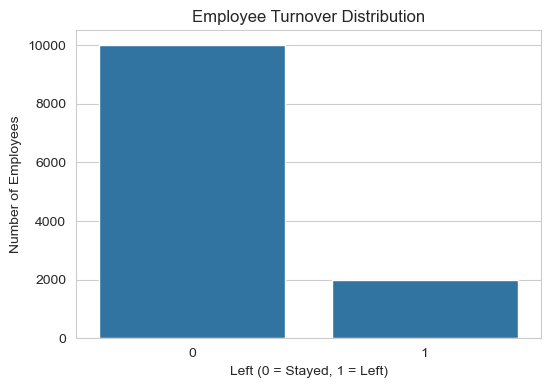

In [5]:
print(df["left"].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="left")
plt.title("Employee Turnover Distribution")
plt.xlabel("Left (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Employees")
plt.show()

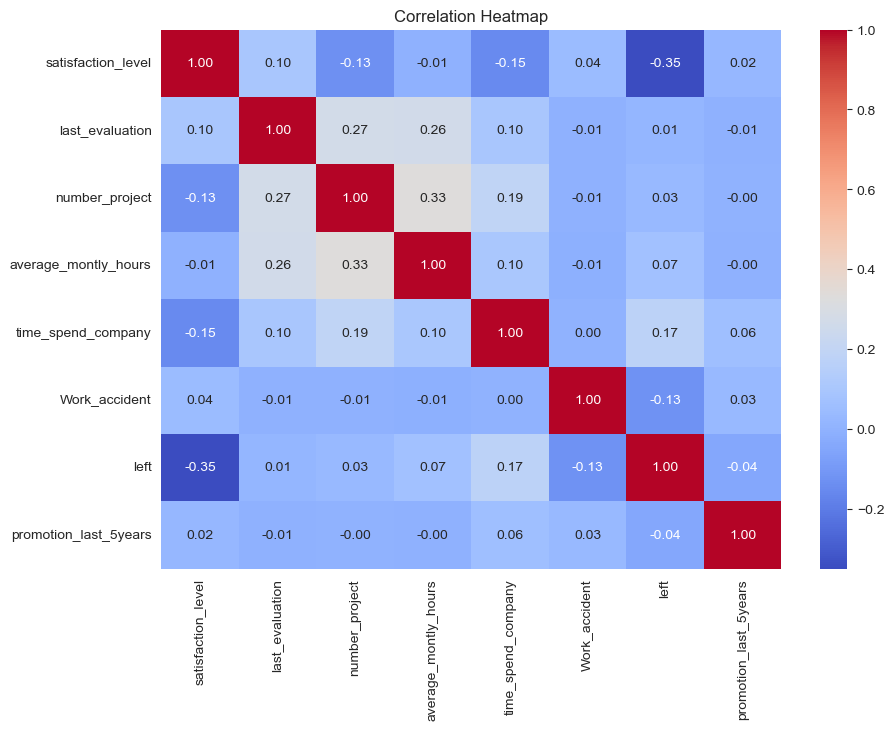

In [6]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

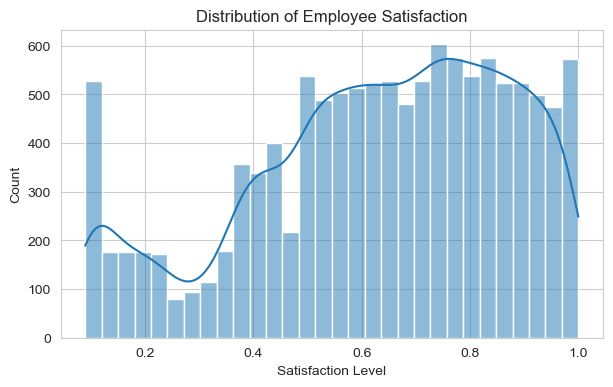

In [7]:
plt.figure(figsize=(7, 4))
sns.histplot(df["satisfaction_level"], bins=30, kde=True)
plt.title("Distribution of Employee Satisfaction")
plt.xlabel("Satisfaction Level")
plt.show()

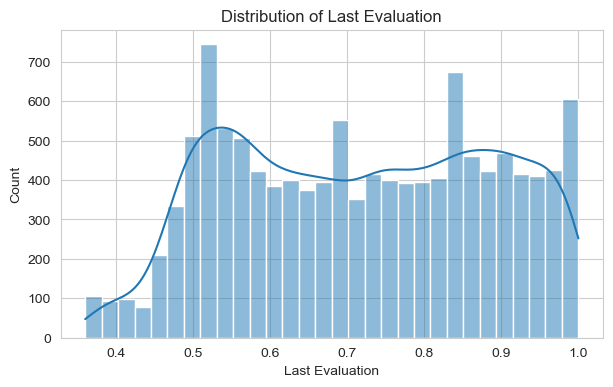

In [8]:
plt.figure(figsize=(7, 4))
sns.histplot(df["last_evaluation"], bins=30, kde=True)
plt.title("Distribution of Last Evaluation")
plt.xlabel("Last Evaluation")
plt.show()

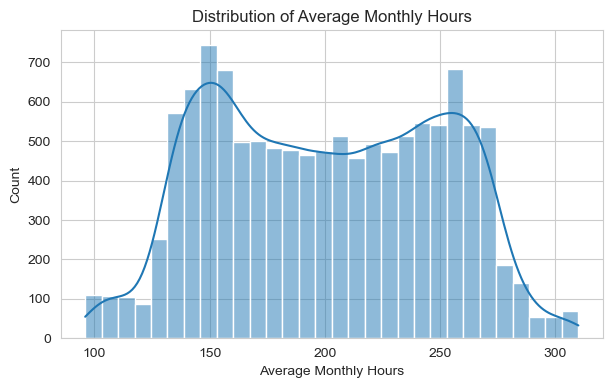

In [9]:
plt.figure(figsize=(7, 4))
sns.histplot(df["average_montly_hours"], bins=30, kde=True)
plt.title("Distribution of Average Monthly Hours")
plt.xlabel("Average Monthly Hours")
plt.show()

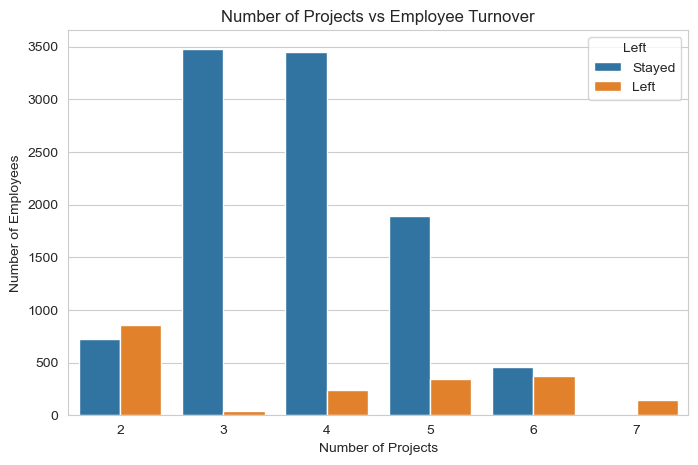

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="number_project",
    hue="left"
)

plt.title("Number of Projects vs Employee Turnover")
plt.xlabel("Number of Projects")
plt.ylabel("Number of Employees")
plt.legend(title="Left", labels=["Stayed", "Left"])
plt.show()

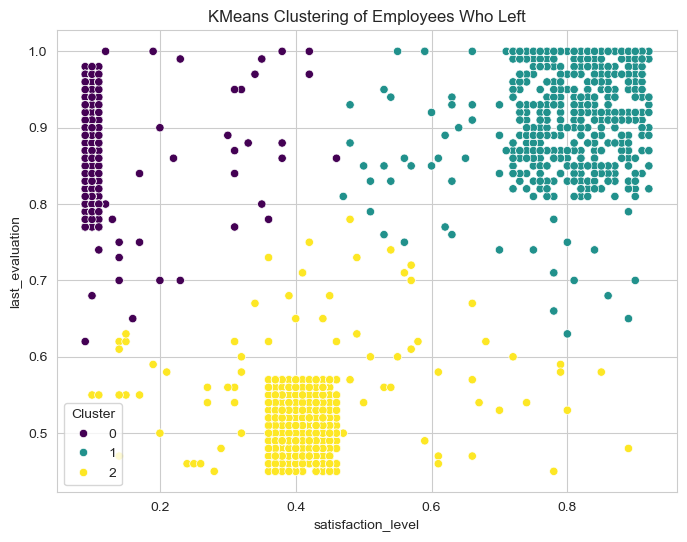

In [11]:
left_employees = df[df["left"] == 1].copy()

X_cluster = left_employees[
    ["satisfaction_level", "last_evaluation"]
]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)

kmeans = KMeans(
    n_clusters=3,
    random_state=123,
    n_init=10
)

left_employees["Cluster"] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=left_employees,
    x="satisfaction_level",
    y="last_evaluation",
    hue="Cluster",
    palette="viridis"
)

plt.title("KMeans Clustering of Employees Who Left")
plt.show()

In [12]:
cluster_summary = left_employees.groupby("Cluster")[
    ["satisfaction_level", "last_evaluation"]
].mean()

print(cluster_summary)

         satisfaction_level  last_evaluation
Cluster                                     
0                  0.111601         0.870923
1                  0.803888         0.915298
2                  0.410992         0.516483


In [13]:
X = df.drop("left", axis=1)
y = df["left"]

# Convert categorical variables into numerical variables
X = pd.get_dummies(X, drop_first=True)

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

X.head()

Feature Shape: (11991, 18)
Target Shape: (11991,)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,False,False,False,False,False,False,True,False,False,True,False
1,0.80,0.86,5,262,6,0,0,False,False,False,False,False,False,True,False,False,False,True
2,0.11,0.88,7,272,4,0,0,False,False,False,False,False,False,True,False,False,False,True
3,0.72,0.87,5,223,5,0,0,False,False,False,False,False,False,True,False,False,True,False
4,0.37,0.52,2,159,3,0,0,False,False,False,False,False,False,True,False,False,True,False


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=123,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Data: (9592, 18)
Testing Data: (2399, 18)

Training Target Distribution:
left
0    0.833924
1    0.166076
Name: proportion, dtype: float64

Testing Target Distribution:
left
0    0.834098
1    0.165902
Name: proportion, dtype: float64


In [15]:
print("Before SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=123)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train,
    y_train
)

print("\nAfter SMOTE:")
print(pd.Series(y_train_resampled).value_counts())

Before SMOTE:
left
0    7999
1    1593
Name: count, dtype: int64

After SMOTE:
left
0    7999
1    7999
Name: count, dtype: int64


In [16]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=123
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=123,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=123
    )
}

In [17]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

cv_results = {}

for name, model in models.items():

    pipeline = ImbPipeline([
        ("smote", SMOTE(random_state=123)),
        ("model", model)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    cv_results[name] = scores.mean()

    print(name)
    print("F1 Scores:", scores)
    print("Mean F1 Score:", scores.mean())
    print("-" * 40)

Logistic Regression
F1 Scores: [0.50813517 0.53727811 0.50253807 0.53836478 0.535     ]
Mean F1 Score: 0.5242632252820563
----------------------------------------
Random Forest
F1 Scores: [0.92551506 0.93610224 0.93904448 0.95008052 0.94041868]
Mean F1 Score: 0.9382321935581247
----------------------------------------
Gradient Boosting
F1 Scores: [0.92307692 0.90909091 0.90909091 0.91551459 0.92117465]
Mean F1 Score: 0.9155895972867605
----------------------------------------


,Model,Mean F1 Score
1,Random Forest,0.938232
2,Gradient Boosting,0.915590
0,Logistic Regression,0.524263


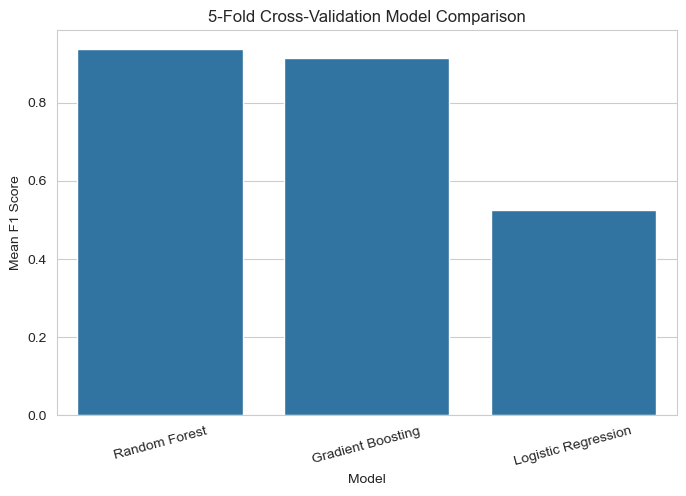

In [18]:
cv_df = pd.DataFrame({
    "Model": list(cv_results.keys()),
    "Mean F1 Score": list(cv_results.values())
})

cv_df = cv_df.sort_values(
    by="Mean F1 Score",
    ascending=False
)

display(cv_df)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=cv_df,
    x="Model",
    y="Mean F1 Score"
)

plt.title("5-Fold Cross-Validation Model Comparison")
plt.xticks(rotation=15)
plt.show()

In [19]:
trained_models = {}
evaluation_results = {}

for name, model in models.items():

    pipeline = ImbPipeline([
        ("smote", SMOTE(random_state=123)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline

    evaluation_results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    }

    print("\n", name)
    print(classification_report(y_test, y_pred))


 Logistic Regression
              precision    recall  f1-score   support

           0       0.92      0.82      0.87      2001
           1       0.43      0.66      0.52       398

    accuracy                           0.80      2399
   macro avg       0.68      0.74      0.69      2399
weighted avg       0.84      0.80      0.81      2399


 Random Forest
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2001
           1       0.94      0.90      0.92       398

    accuracy                           0.97      2399
   macro avg       0.96      0.95      0.95      2399
weighted avg       0.97      0.97      0.97      2399


 Gradient Boosting
              precision    recall  f1-score   support

           0       0.98      0.97      0.98      2001
           1       0.87      0.92      0.89       398

    accuracy                           0.96      2399
   macro avg       0.92      0.95      0.94      2399
weighted avg    

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Logistic Regression,0.795748,0.425806,0.663317,0.518664,0.803453
Random Forest,0.974990,0.942408,0.904523,0.923077,0.975773
Gradient Boosting,0.963318,0.865566,0.922111,0.892944,0.978763


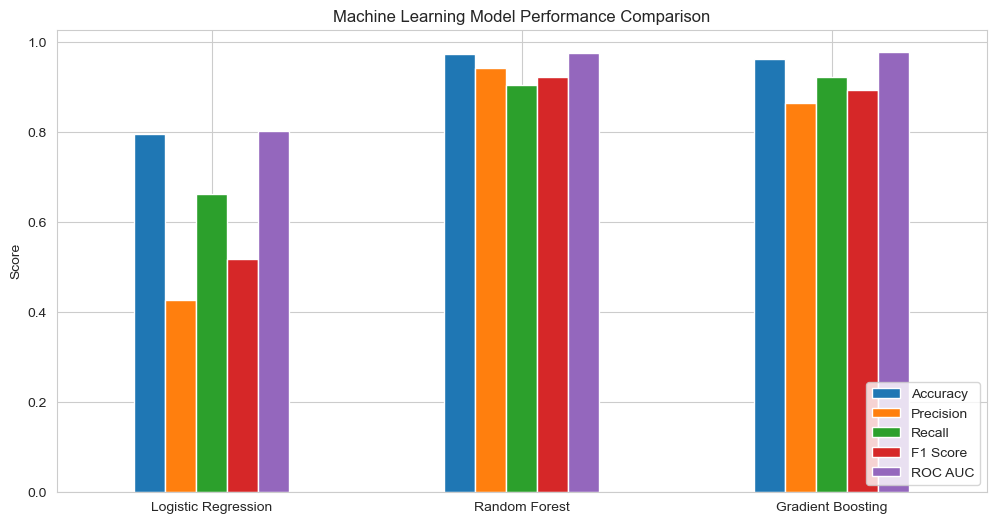

In [20]:
results_df = pd.DataFrame(
    evaluation_results
).T

display(results_df)

results_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

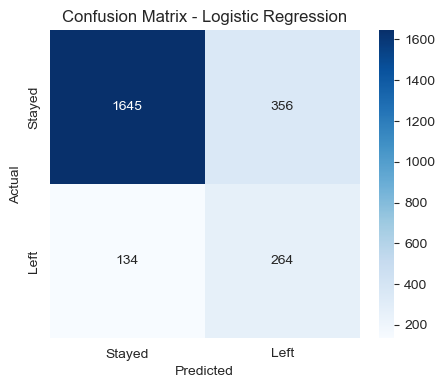

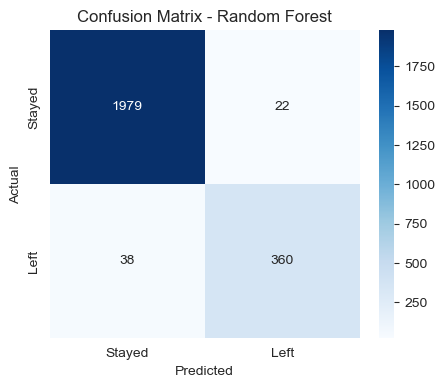

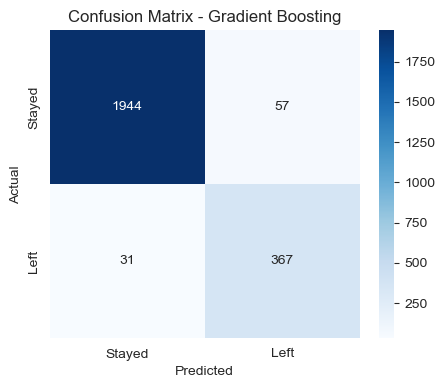

In [21]:
for name, pipeline in trained_models.items():

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Stayed", "Left"],
        yticklabels=["Stayed", "Left"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

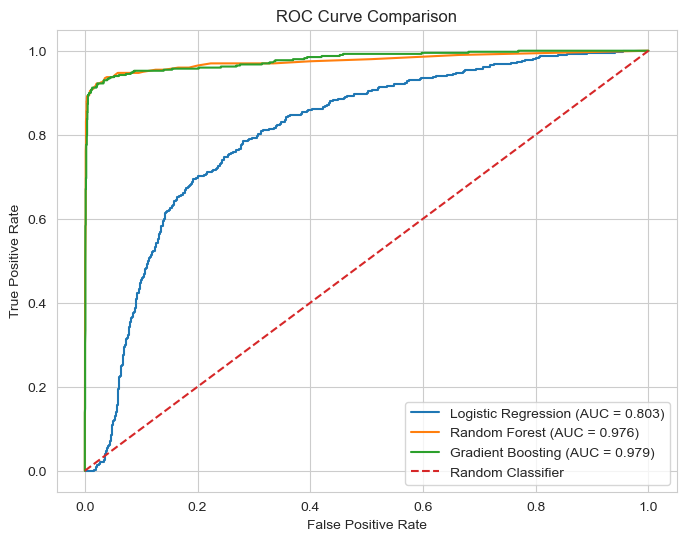

In [22]:
plt.figure(figsize=(8, 6))

for name, pipeline in trained_models.items():

    y_prob = pipeline.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [23]:
best_model_name = results_df["F1 Score"].idxmax()

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("\nPerformance:")
print(results_df.loc[best_model_name])

Best Model: Random Forest

Performance:
Accuracy     0.974990
Precision    0.942408
Recall       0.904523
F1 Score     0.923077
ROC AUC      0.975773
Name: Random Forest, dtype: float64


In [24]:
turnover_probabilities = best_model.predict_proba(X_test)[:, 1]

predictions_df = X_test.copy()

predictions_df["Actual"] = y_test.values

predictions_df["Turnover_Probability"] = turnover_probabilities

predictions_df["Turnover_Probability_Percentage"] = (
    predictions_df["Turnover_Probability"] * 100
)

display(
    predictions_df[
        ["Actual", "Turnover_Probability_Percentage"]
    ].head(10)
)

,Actual,Turnover_Probability_Percentage
8578,0,6.0
5756,0,35.0
3994,0,2.0
1784,1,94.0
10508,0,2.0
1539,1,98.0
8563,0,3.0
6163,0,1.0
4239,0,1.0
7919,0,0.0


In [25]:
def risk_zone(probability):

    if probability < 0.20:
        return "Safe"

    elif probability < 0.60:
        return "Low"

    elif probability <= 0.90:
        return "Medium"

    else:
        return "High"


predictions_df["Risk_Zone"] = (
    predictions_df["Turnover_Probability"].apply(risk_zone)
)

display(
    predictions_df[
        ["Actual", "Turnover_Probability_Percentage", "Risk_Zone"]
    ].head(20)
)

,Actual,Turnover_Probability_Percentage,Risk_Zone
8578,0,6.0,Safe
5756,0,35.0,Low
3994,0,2.0,Safe
1784,1,94.0,High
10508,0,2.0,Safe
1539,1,98.0,High
8563,0,3.0,Safe
6163,0,1.0,Safe
4239,0,1.0,Safe
7919,0,0.0,Safe


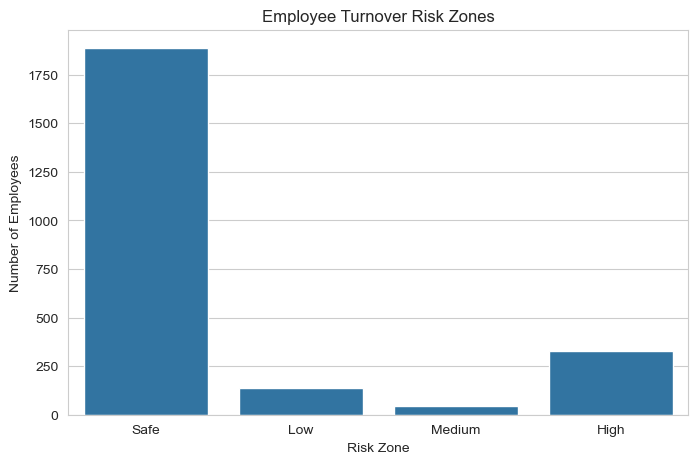

In [26]:
risk_counts = predictions_df["Risk_Zone"].value_counts()

risk_order = ["Safe", "Low", "Medium", "High"]

risk_counts = risk_counts.reindex(
    risk_order,
    fill_value=0
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=risk_counts.index,
    y=risk_counts.values
)

plt.title("Employee Turnover Risk Zones")
plt.xlabel("Risk Zone")
plt.ylabel("Number of Employees")
plt.show()

In [27]:
risk_percentages = (
    predictions_df["Risk_Zone"]
    .value_counts(normalize=True) * 100
)

risk_percentages = risk_percentages.reindex(
    risk_order,
    fill_value=0
)

print("Employee Risk Zone Distribution (%):")

display(risk_percentages.round(2))

Employee Risk Zone Distribution (%):


Risk_Zone
Safe      78.66
Low        5.79
Medium     1.83
High      13.71
Name: proportion, dtype: float64

In [28]:
high_risk_employees = predictions_df[
    predictions_df["Risk_Zone"] == "High"
]

print("Number of High-Risk Employees:", len(high_risk_employees))

display(high_risk_employees.head(20))

Number of High-Risk Employees: 329


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,...,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium,Actual,Turnover_Probability,Turnover_Probability_Percentage,Risk_Zone
1784,0.43,0.51,2,149,3,1,0,False,True,False,...,False,False,False,False,False,True,1,0.94,94.0,High
1539,0.83,0.92,4,235,5,0,0,False,False,False,...,False,True,False,False,True,False,1,0.98,98.0,High
452,0.10,0.87,6,286,4,0,0,False,False,False,...,False,False,False,False,False,True,1,1.00,100.0,High
795,0.43,0.54,2,150,3,0,0,False,False,True,...,False,False,False,False,True,False,1,1.00,100.0,High
681,0.40,0.49,2,128,3,0,0,False,False,False,...,False,True,False,False,True,False,1,1.00,100.0,High
1223,0.75,0.89,4,228,5,0,0,False,False,False,...,False,False,True,False,True,False,1,0.98,98.0,High
540,0.45,0.54,2,129,3,0,0,False,False,False,...,False,False,False,False,False,False,1,0.92,92.0,High
1566,0.10,0.96,6,274,4,0,0,False,False,False,...,False,False,False,True,True,False,1,1.00,100.0,High
1190,0.11,0.89,6,264,4,0,0,False,False,False,...,False,False,True,False,True,False,1,1.00,100.0,High
1538,0.41,0.54,2,135,3,0,0,False,False,False,...,False,True,False,False,True,False,1,1.00,100.0,High


In [29]:
retention_strategies = {
    "Safe": "Continue regular engagement and employee satisfaction surveys.",

    "Low": "Monitor employee satisfaction and provide career development opportunities.",

    "Medium": "Conduct one-to-one meetings, review workload, and identify employee concerns.",

    "High": "Arrange immediate HR intervention, discuss compensation, workload, career growth, and workplace concerns."
}

for zone, strategy in retention_strategies.items():

    print("\nRisk Zone:", zone)
    print("Recommended Strategy:", strategy)


Risk Zone: Safe
Recommended Strategy: Continue regular engagement and employee satisfaction surveys.

Risk Zone: Low
Recommended Strategy: Monitor employee satisfaction and provide career development opportunities.

Risk Zone: Medium
Recommended Strategy: Conduct one-to-one meetings, review workload, and identify employee concerns.

Risk Zone: High
Recommended Strategy: Arrange immediate HR intervention, discuss compensation, workload, career growth, and workplace concerns.


In [30]:
print("=" * 55)
print("EMPLOYEE TURNOVER PREDICTION - FINAL SUMMARY")
print("=" * 55)

print("\nTotal Employees Analyzed:", len(df))

print("Employees Who Left:", int(df["left"].sum()))

print("Employees Who Stayed:", int((df["left"] == 0).sum()))

print("\nBest Performing Model:", best_model_name)

print("\nModel Performance:")
display(results_df.loc[[best_model_name]])

print("\nEmployee Risk Zone Distribution:")
display(risk_counts)

print("\nProject Completed Successfully!")

EMPLOYEE TURNOVER PREDICTION - FINAL SUMMARY

Total Employees Analyzed: 11991
Employees Who Left: 1991
Employees Who Stayed: 10000

Best Performing Model: Random Forest

Model Performance:


,Accuracy,Precision,Recall,F1 Score,ROC AUC
Random Forest,0.97499,0.942408,0.904523,0.923077,0.975773



Employee Risk Zone Distribution:


Risk_Zone
Safe      1887
Low        139
Medium      44
High       329
Name: count, dtype: int64


Project Completed Successfully!
